# CME519 Data Mining — Midterm Project
## Notebook 1 — Data Acquisition & Exploratory Data Analysis (EDA)

**Student:** Musa AL AHMED (26221001014)
**Project:** Predicting whether pull requests opened by AI coding agents get merged — AIDev dataset
**Dataset:** [hao-li/AIDev](https://huggingface.co/datasets/hao-li/AIDev) (Hugging Face)

This project follows the **CRISP-DM** process. This notebook covers the first two phases:

| CRISP-DM phase | Where |
|---|---|
| 1. Business understanding | Section 1 |
| 2. Data understanding (collection, integration, EDA) | Sections 2–8 (this notebook) |
| 3. Data preparation, feature engineering & selection | Notebook 2 |
| 4–5. Modeling & evaluation | Notebook 3 |

**Outputs of this notebook:** a PR-level dataset saved to Google Drive (`data/pr_level.parquet`) and all EDA figures (`figures/`), which are used in the IEEE report.

## 1. Business understanding

AI coding agents (OpenAI Codex, Devin, GitHub Copilot, Cursor, Claude Code) now open pull requests (PRs) in real open-source projects. Many of these PRs are rejected, which wastes reviewer time.

**Goal.** Predict, *at the moment a PR is opened*, whether it will be **merged (1)** or **closed without merge (0)**, using information about the agent, the repository, the author and the code change.

- **Task type:** supervised, binary classification.
- **Unit of analysis:** one closed pull request.
- **Decision time:** PR creation. Only information available when the PR is opened may be used as a feature. Anything that happens later (merge/close time, reviews, comments) is **data leakage** and is excluded.
- **Success criteria:** the classes are imbalanced, so models are judged mainly with **PR-AUC (average precision), precision and recall** of the minority class, plus ROC-AUC and accuracy for reference, using 5-fold stratified cross-validation (Notebook 3).
- **Use of the result:** the final project will integrate the model into *CleanLens*, a local Clean-Code analysis tool, for early detection of problematic AI-generated changes.

## 2. Setup

The notebook runs on **Google Colab** (recommended) or locally. On Colab it mounts Google Drive so that the processed data and figures are kept between sessions and can be read by Notebooks 2 and 3.

> If the download from Hugging Face asks for authentication, run `from huggingface_hub import login; login()` once and paste a free Hugging Face token.

In [ ]:
import os, sys, time, re, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "huggingface_hub"], check=False)
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = "/content/drive/MyDrive/CME519_AIDev"
    CACHE_DIR = "/content/aidev_cache"          # large raw files stay on the Colab disk, not on Drive
else:
    WORK_DIR = os.environ.get("AIDEV_WORK_DIR", os.path.abspath("CME519_AIDev"))
    CACHE_DIR = os.path.join(WORK_DIR, "raw_cache")

DATA_SOURCE = os.environ.get("AIDEV_BASE", "huggingface")   # "huggingface" or a local folder with the parquet files
DATA_DIR = os.path.join(WORK_DIR, "data")
FIG_DIR = os.path.join(WORK_DIR, "figures")
for d in (DATA_DIR, FIG_DIR, CACHE_DIR):
    os.makedirs(d, exist_ok=True)

def save_fig(name):
    path = os.path.join(FIG_DIR, f"{name}.png")
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("figure saved ->", path)

print("Running on Colab:", IN_COLAB)
print("Work dir        :", WORK_DIR)
print("Data source     :", DATA_SOURCE)
print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

Mounted at /content/drive
Running on Colab: True
Work dir        : /content/drive/MyDrive/CME519_AIDev
Data source     : huggingface
pandas 2.2.3 | numpy 2.4.6 | seaborn 0.13.2


## 3. Data collection

AIDev is a relational dataset. The curated subset (**AIDev-pop**, repositories with >100 GitHub stars) contains PR-level tables plus commit and file-level change tables. The tables used here:

| Table | Grain | Used for |
|---|---|---|
| `pull_request` | 1 row per PR | target, agent, title/body, creation time |
| `repository` | 1 row per repo | language, license, stars, forks, fork flag |
| `user` | 1 row per PR author | followers, following, account creation date |
| `pr_commits` | 1 row per commit | number of commits per PR |
| `pr_commit_details` | 1 row per changed file per commit (~12M rows, 1.3 GB) | size and type of the code change |

**Deliberately not used as features:** `pr_reviews`, `pr_comments`, `pr_review_comments`, `pr_timeline`. They describe events that happen **after** the PR is opened (reviews, discussion, merge), so using them would leak the answer.

In [ ]:
def get_file(name):
    # Return a local path to <name>.parquet, downloading it from Hugging Face on first use.
    if DATA_SOURCE != "huggingface":
        return os.path.join(DATA_SOURCE, f"{name}.parquet")
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo_id="hao-li/AIDev", repo_type="dataset",
                           filename=f"{name}.parquet", local_dir=CACHE_DIR)

def read_table(name, columns=None):
    t0 = time.time()
    df = pd.read_parquet(get_file(name), columns=columns)
    mem = df.memory_usage(deep=True).sum() / 1e6
    print(f"{name:<18} {df.shape[0]:>10,} rows x {df.shape[1]:>2} cols  | {mem:,.0f} MB | {time.time()-t0:.1f}s")
    return df

pr_raw   = read_table("pull_request")
repo_raw = read_table("repository")
user_raw = read_table("all_user")

pull_request          361,296 rows x 14 cols  | 2,504 MB | 17.4s
repository             25,402 rows x  8 cols  | 8 MB | 0.3s


all_user.parquet: reconstructing file:   0%|          |  0.00B / 13.6MB            

all_user.parquet: downloading bytes:           |  0.00B            

all_user              399,962 rows x  5 cols  | 61 MB | 4.9s


In [ ]:
print("pull_request columns:", list(pr_raw.columns))
pr_raw.info()
pr_raw.head(3)

pull_request columns: ['id', 'number', 'title', 'body', 'agent', 'user_id', 'user', 'state', 'created_at', 'closed_at', 'merged_at', 'repo_id', 'repo_url', 'html_url']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 361296 entries, 0 to 361295
Data columns (total 14 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   id          361296 non-null  int64 
 1   number      361296 non-null  int64 
 2   title       361296 non-null  object
 3   body        359538 non-null  object
 4   agent       361296 non-null  object
 5   user_id     361296 non-null  int64 
 6   user        361296 non-null  object
 7   state       361296 non-null  object
 8   created_at  361296 non-null  object
 9   closed_at   332406 non-null  object
 10  merged_at   246777 non-null  object
 11  repo_id     361296 non-null  int64 
 12  repo_url    361296 non-null  object
 13  html_url    361296 non-null  object
dtypes: int64(4), object(10)
memory usage: 38.6+ MB


,id,number,title,body,agent,user_id,user,state,created_at,closed_at,merged_at,repo_id,repo_url,html_url
0,3256881529,3690,Add Node version check to preflight,## Summary\n- verify Node.js installation in `...,OpenAI_Codex,24208299,MontrealAI,closed,2025-07-23T15:44:16Z,2025-07-23T15:44:29Z,2025-07-23T15:44:29Z,922805069,https://api.github.com/repos/MontrealAI/AGI-Al...,https://github.com/MontrealAI/AGI-Alpha-Agent-...
1,3122476985,24,Improve README setup instructions,## Summary\n- expand README with prerequisites...,OpenAI_Codex,1387285,puncsky,open,2025-06-05T19:57:59Z,None,None,793852040,https://api.github.com/repos/cuckoo-network/cu...,https://github.com/cuckoo-network/cuckoo/pull/24
2,3122488612,62,Disable chord key play while editing text,## Summary\n- don't play chord sounds when key...,OpenAI_Codex,1034155,charlesvestal,closed,2025-06-05T20:01:46Z,2025-06-05T20:03:40Z,2025-06-05T20:03:40Z,922867547,https://api.github.com/repos/charlesvestal/ext...,https://github.com/charlesvestal/extending-mov...


In [ ]:
print("repository columns:", list(repo_raw.columns))
print("user columns      :", list(user_raw.columns))
display(repo_raw.head(3))
display(user_raw.head(3))

repository columns: ['id', 'url', 'license', 'full_name', 'is_forked', 'language', 'forks', 'stars']
user columns      : ['id', 'login', 'followers', 'following', 'created_at']


,id,url,license,full_name,is_forked,language,forks,stars
0,922873328,https://api.github.com/repos/willmiao/ComfyUI-...,GPL-3.0,willmiao/ComfyUI-Lora-Manager,False,Python,101,1065
1,373383253,https://api.github.com/repos/hoc081098/FlowExt,MIT,hoc081098/FlowExt,False,Kotlin,28,416
2,651622038,https://api.github.com/repos/allenai/open-inst...,Apache-2.0,allenai/open-instruct,False,Python,531,3684


,id,login,followers,following,created_at
0,"238,120,892.000",vilelaassessoriasc-hue,0.000,0.000,2025-10-15T01:04:18Z
1,"117,571,344.000",dylanngn,0.000,1.000,2022-11-06T10:44:21Z
2,"12,562,703.000",teweldemat,0.000,0.000,2015-05-22T16:14:35Z


## 4. Scope and target definition

- Only **closed** PRs have a known outcome. Open PRs are excluded (their label is unknown).
- **Target:** `merged = 1` if `merged_at` is not null, otherwise `0`.

PR state counts (all PRs):
state
closed    332406
open       28890 

Closed PRs kept for modeling: 332,406


,count,percent
0 = not merged,85629,25.760
1 = merged,246777,74.240


figure saved -> /content/drive/MyDrive/CME519_AIDev/figures/01_target_distribution.png


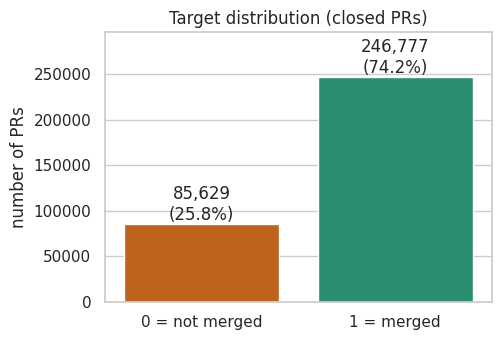

Interpretation: the minority class is 25.8% of the data -> the dataset is moderately imbalanced. Accuracy alone would be misleading; PR-AUC, precision and recall will be reported and stratified splits will be used.


In [ ]:
print("PR state counts (all PRs):")
print(pr_raw["state"].value_counts(dropna=False).to_string(), "\n")

pr = pr_raw[pr_raw["state"] == "closed"].copy()
pr["merged"] = pr["merged_at"].notna().astype("int8")

counts = pr["merged"].value_counts().sort_index()
share = pr["merged"].value_counts(normalize=True).sort_index() * 100
target_tbl = pd.DataFrame({"count": counts, "percent": share.round(2)})
target_tbl.index = ["0 = not merged", "1 = merged"]
print(f"Closed PRs kept for modeling: {len(pr):,}")
display(target_tbl)

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=target_tbl.index, y=target_tbl["count"], ax=ax, palette=["#d95f02", "#1b9e77"])
for i, (c, p) in enumerate(zip(target_tbl["count"], target_tbl["percent"])):
    ax.text(i, c, f"{c:,}\n({p:.1f}%)", ha="center", va="bottom")
ax.set_title("Target distribution (closed PRs)"); ax.set_xlabel(""); ax.set_ylabel("number of PRs")
ax.set_ylim(0, target_tbl["count"].max() * 1.2)
save_fig("01_target_distribution"); plt.show()

minority = share.min()
print(f"Interpretation: the minority class is {minority:.1f}% of the data -> the dataset is "
      f"{'moderately' if minority > 20 else 'strongly'} imbalanced. Accuracy alone would be misleading; "
      f"PR-AUC, precision and recall will be reported and stratified splits will be used.")

## 5. Commit and file-level data → PR-level features

`pr_commit_details` has one row per changed file per commit (~12 million rows). Loading it whole would exceed Colab's memory, so it is read **in batches**, only the needed columns are read (the large `patch` text is skipped), and the rows are aggregated to one row per PR.

| Feature | Meaning |
|---|---|
| `n_commits` | number of commits in the PR |
| `n_file_changes` | number of file changes (summed over commits) |
| `additions`, `deletions`, `changes` | lines added / deleted / changed |
| `max_file_changes` | largest single-file change |
| `n_test_files`, `n_doc_files`, `n_config_files` | changes to test, documentation and configuration files |
| `n_added_files`, `n_removed_files`, `n_renamed_files` | file status counts |
| `n_distinct_ext` | number of distinct file extensions touched |

> **Leakage note:** commits pushed after a reviewer's feedback are also counted here. Notebook 3 tests the models with and without these commit-based features to check that the results do not depend on them.

In [ ]:
closed_ids = pd.Index(pr["id"].unique())

commits = read_table("pr_commits", columns=["sha", "pr_id"])
commits = commits[commits["pr_id"].isin(closed_ids)]
n_commits = commits.groupby("pr_id")["sha"].nunique().rename("n_commits")
del commits
print(f"PRs with commit info: {len(n_commits):,}")
n_commits.describe()

pr_commits.parquet: reconstructing file:   0%|          |  0.00B /  341MB            

pr_commits.parquet: downloading bytes:           |  0.00B            

pr_commits          1,718,829 rows x  2 cols  | 167 MB | 10.5s
PRs with commit info: 331,010


,n_commits
count,"331,010.000"
mean,4.639
std,14.271
min,1.000
25%,1.000
50%,2.000
75%,4.000
max,250.000


In [ ]:
TEST_RE   = r"(?:^|/)(?:tests?|__tests__|spec|specs)/|(?:^|/)test_|_test\.|\.test\.|\.spec\."
DOC_RE    = r"\.(?:md|rst|txt|adoc)$|(?:^|/)docs?/"
CONFIG_RE = r"\.(?:json|ya?ml|toml|ini|cfg|lock|xml|gradle)$|dockerfile|makefile|(?:^|/)\.github/"

path = get_file("pr_commit_details")
pf = pq.ParquetFile(path)
print(f"pr_commit_details: {pf.metadata.num_rows:,} rows in {pf.num_row_groups} row groups")

cols = ["pr_id", "filename", "status", "additions", "deletions", "changes"]
agg_parts, ext_parts, seen = [], [], 0
t0 = time.time()
for i, batch in enumerate(pf.iter_batches(batch_size=1_000_000, columns=cols)):
    ch = batch.to_pandas()
    seen += len(ch)
    ch = ch[ch["pr_id"].isin(closed_ids)]
    fn = ch["filename"].fillna("").str.lower()
    ch = ch.assign(
        is_test=fn.str.contains(TEST_RE, regex=True),
        is_doc=fn.str.contains(DOC_RE, regex=True),
        is_config=fn.str.contains(CONFIG_RE, regex=True),
        st_added=ch["status"].eq("added"),
        st_removed=ch["status"].eq("removed"),
        st_renamed=ch["status"].eq("renamed"),
        ext=fn.str.extract(r"\.([a-z0-9]{1,8})$", expand=False).fillna("noext"),
    )
    g = ch.groupby("pr_id").agg(
        n_file_changes=("filename", "size"),
        additions=("additions", "sum"), deletions=("deletions", "sum"), changes=("changes", "sum"),
        max_file_changes=("changes", "max"),
        n_test_files=("is_test", "sum"), n_doc_files=("is_doc", "sum"), n_config_files=("is_config", "sum"),
        n_added_files=("st_added", "sum"), n_removed_files=("st_removed", "sum"), n_renamed_files=("st_renamed", "sum"),
    )
    agg_parts.append(g)
    ext_parts.append(ch[["pr_id", "ext"]].drop_duplicates())
    print(f"  batch {i+1}: {seen:,} rows read | {time.time()-t0:.0f}s")

agg = pd.concat(agg_parts)
sum_cols = [c for c in agg.columns if c != "max_file_changes"]
file_feats = agg.groupby(level=0)[sum_cols].sum()
file_feats["max_file_changes"] = agg.groupby(level=0)["max_file_changes"].max()
exts = pd.concat(ext_parts).drop_duplicates()
file_feats["n_distinct_ext"] = exts.groupby("pr_id").size()
file_feats.index.name = "pr_id"
del agg_parts, ext_parts, agg, exts
print(f"PR-level file features: {file_feats.shape[0]:,} PRs x {file_feats.shape[1]} features")
file_feats.head()

pr_commit_details.parquet: reconstructing file:   0%|          |  0.00B / 12.4GB            

pr_commit_details.parquet: downloading bytes:           |  0.00B            

pr_commit_details: 12,116,310 rows in 61 row groups
  batch 1: 1,000,000 rows read | 9s
  batch 2: 2,000,000 rows read | 20s
  batch 3: 3,000,000 rows read | 33s
  batch 4: 4,000,000 rows read | 42s
  batch 5: 5,000,000 rows read | 55s
  batch 6: 6,000,000 rows read | 67s
  batch 7: 7,000,000 rows read | 77s
  batch 8: 8,000,000 rows read | 90s
  batch 9: 9,000,000 rows read | 102s
  batch 10: 10,000,000 rows read | 116s
  batch 11: 11,000,000 rows read | 127s
  batch 12: 12,000,000 rows read | 138s
  batch 13: 12,116,310 rows read | 138s
PR-level file features: 331,008 PRs x 12 features


,n_file_changes,additions,deletions,changes,n_test_files,n_doc_files,n_config_files,n_added_files,n_removed_files,n_renamed_files,max_file_changes,n_distinct_ext
pr_id,,,,,,,,,,,,
2756921963,74,848.000,344.000,"1,192.000",55,0,5,7,0,0,128.000,3
2757103560,33,517.000,262.000,779.000,2,0,6,1,0,0,152.000,3
2757124156,1,1.000,1.000,2.000,0,1,0,0,0,0,2.000,1
2757125491,1,1.000,1.000,2.000,0,1,0,0,0,0,2.000,1
2757179026,21,"1,633.000",169.000,"1,802.000",19,0,0,13,0,0,450.000,1


## 6. Data integration — one row per PR

The tables are joined on their keys (`repo_id → repository.id`, `user_id → user.id`, `id → pr_id`). Prefixes `repo_` and `user_` make the origin of each column clear.

In [ ]:
repo = repo_raw.rename(columns={"id": "repo_id", "license": "repo_license", "full_name": "repo_full_name",
                                "is_forked": "repo_is_forked", "language": "repo_language",
                                "forks": "repo_forks", "stars": "repo_stars"}).drop(columns=["url"], errors="ignore")

if "id" not in user_raw.columns:          # safety: keep going even if the user table has another layout
    user_raw = pd.DataFrame(columns=["id"])
user = user_raw.rename(columns={"id": "user_id", "followers": "user_followers", "following": "user_following",
                                "created_at": "user_created_at"}).drop(columns=["login"], errors="ignore")
user["user_id"] = pd.to_numeric(user["user_id"], errors="coerce").astype("Int64")
user = user.drop_duplicates("user_id")

df = pr.copy()
df["user_id"] = df["user_id"].astype("Int64")
df = df.merge(repo, on="repo_id", how="left")
df = df.merge(user, on="user_id", how="left")
df = df.merge(n_commits, left_on="id", right_index=True, how="left")
df = df.merge(file_feats, left_on="id", right_index=True, how="left")

for c in ["created_at", "closed_at", "merged_at", "user_created_at"]:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], utc=True, errors="coerce")

print(f"Integrated dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("Rows without repository info:", df["repo_stars"].isna().sum())
print("Rows without user info      :", df["user_followers"].isna().sum() if "user_followers" in df else "n/a")
print("Rows without file info      :", df["n_file_changes"].isna().sum())
df.head(3)

Integrated dataset: 332,406 rows x 37 columns
Rows without repository info: 0
Rows without user info      : 90886
Rows without file info      : 1398


,id,number,title,body,agent,user_id,user,state,created_at,closed_at,merged_at,repo_id,repo_url,html_url,merged,repo_license,repo_full_name,repo_is_forked,repo_language,repo_forks,repo_stars,user_followers,user_following,user_created_at,n_commits,n_file_changes,additions,deletions,changes,n_test_files,n_doc_files,n_config_files,n_added_files,n_removed_files,n_renamed_files,max_file_changes,n_distinct_ext
0,3256881529,3690,Add Node version check to preflight,## Summary\n- verify Node.js installation in `...,OpenAI_Codex,24208299,MontrealAI,closed,2025-07-23 15:44:16+00:00,2025-07-23 15:44:29+00:00,2025-07-23 15:44:29+00:00,922805069,https://api.github.com/repos/MontrealAI/AGI-Al...,https://github.com/MontrealAI/AGI-Alpha-Agent-...,1,Apache-2.0,MontrealAI/AGI-Alpha-Agent-v0,False,Python,62,283,215.000,1.000,2016-11-27 14:57:16+00:00,1.000,1.000,21.000,0.000,21.000,0.000,0.000,0.000,0.000,0.000,0.000,21.000,1.000
1,3122488612,62,Disable chord key play while editing text,## Summary\n- don't play chord sounds when key...,OpenAI_Codex,1034155,charlesvestal,closed,2025-06-05 20:01:46+00:00,2025-06-05 20:03:40+00:00,2025-06-05 20:03:40+00:00,922867547,https://api.github.com/repos/charlesvestal/ext...,https://github.com/charlesvestal/extending-mov...,1,MIT,charlesvestal/extending-move,False,Python,9,155,62.000,2.000,2011-09-07 21:50:34+00:00,1.000,1.000,5.000,0.000,5.000,0.000,0.000,0.000,0.000,0.000,0.000,5.000,1.000
2,3087726186,666,[alpha_factory] Update offline setup docs,## Summary\n- clarify offline `check_env.py` u...,OpenAI_Codex,24208299,MontrealAI,closed,2025-05-23 23:39:13+00:00,2025-05-23 23:39:23+00:00,2025-05-23 23:39:23+00:00,922805069,https://api.github.com/repos/MontrealAI/AGI-Al...,https://github.com/MontrealAI/AGI-Alpha-Agent-...,1,Apache-2.0,MontrealAI/AGI-Alpha-Agent-v0,False,Python,62,283,215.000,1.000,2016-11-27 14:57:16+00:00,1.000,1.000,3.000,0.000,3.000,0.000,1.000,0.000,0.000,0.000,0.000,3.000,1.000


### 6.1 Column roles

Every column gets a role. This table is used in Notebook 2 to decide what can be a model input.

In [ ]:
ROLES = {
    "id_or_meta": ["id", "number", "repo_id", "user_id", "user", "repo_full_name", "repo_url", "html_url"],
    "target": ["merged"],
    "leakage_excluded": ["state", "closed_at", "merged_at"],
    "text": ["title", "body"],
    "datetime": ["created_at", "user_created_at"],
    "categorical": ["agent", "repo_language", "repo_license", "repo_is_forked"],
    "numeric": ["repo_stars", "repo_forks", "user_followers", "user_following", "n_commits",
                "n_file_changes", "additions", "deletions", "changes", "max_file_changes",
                "n_test_files", "n_doc_files", "n_config_files", "n_added_files", "n_removed_files",
                "n_renamed_files", "n_distinct_ext"],
}
ROLES = {k: [c for c in v if c in df.columns] for k, v in ROLES.items()}
role_tbl = pd.DataFrame([(r, len(cs), ", ".join(cs)) for r, cs in ROLES.items()],
                        columns=["role", "n_columns", "columns"])
display(role_tbl)

n_cand = len(ROLES["numeric"]) + len(ROLES["categorical"]) + len(ROLES["datetime"]) + len(ROLES["text"])
print(f"Candidate input features before feature engineering: {n_cand} "
      f"({len(ROLES['numeric'])} numeric, {len(ROLES['categorical'])} categorical, "
      f"{len(ROLES['datetime'])} datetime, {len(ROLES['text'])} text)")

NUM = ROLES["numeric"]; CAT = ROLES["categorical"]
out_path = os.path.join(DATA_DIR, "pr_level.parquet")
df.to_parquet(out_path, index=False)
print("Saved ->", out_path, f"({os.path.getsize(out_path)/1e6:,.0f} MB)")

,role,n_columns,columns
0,id_or_meta,8,"id, number, repo_id, user_id, user, repo_full_..."
1,target,1,merged
2,leakage_excluded,3,"state, closed_at, merged_at"
3,text,2,"title, body"
4,datetime,2,"created_at, user_created_at"
5,categorical,4,"agent, repo_language, repo_license, repo_is_fo..."
6,numeric,17,"repo_stars, repo_forks, user_followers, user_f..."


Candidate input features before feature engineering: 25 (17 numeric, 4 categorical, 2 datetime, 2 text)
Saved -> /content/drive/MyDrive/CME519_AIDev/data/pr_level.parquet (332 MB)


## 7. Exploratory Data Analysis
### 7.1 Missing values

,missing_%
user_following,27.340
user_followers,27.340
user_created_at,27.340
repo_license,4.460
max_file_changes,2.860
repo_language,0.640
body,0.490
n_distinct_ext,0.420
n_renamed_files,0.420
n_file_changes,0.420


figure saved -> /content/drive/MyDrive/CME519_AIDev/figures/02_missing_values.png


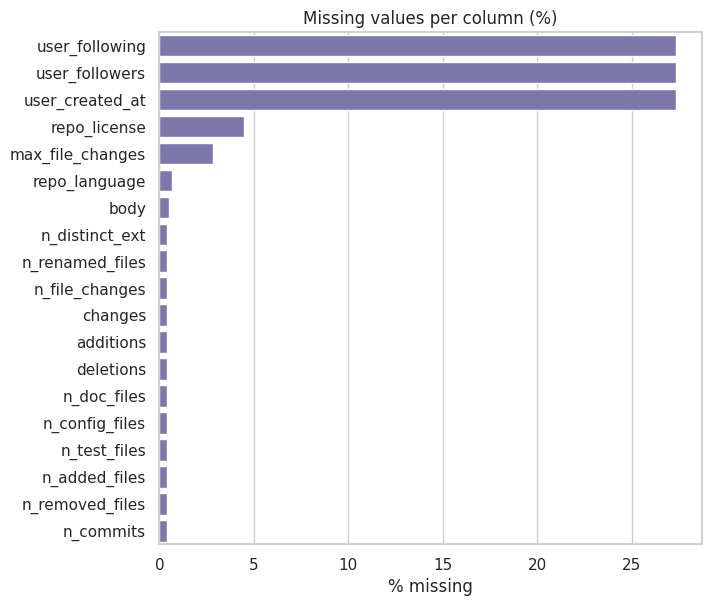

Interpretation:
  - user_following: 27.34% missing -> impute + missing indicator
  - user_followers: 27.34% missing -> impute + missing indicator
  - user_created_at: 27.34% missing -> impute + missing indicator
  - repo_license: 4.46% missing -> simple imputation
  - max_file_changes: 2.86% missing -> simple imputation
  - repo_language: 0.64% missing -> simple imputation
  - body: 0.49% missing -> simple imputation
  - n_distinct_ext: 0.42% missing -> simple imputation
  - n_renamed_files: 0.42% missing -> simple imputation
  - n_file_changes: 0.42% missing -> simple imputation
  - changes: 0.42% missing -> simple imputation
  - additions: 0.42% missing -> simple imputation
  - deletions: 0.42% missing -> simple imputation
  - n_doc_files: 0.42% missing -> simple imputation
  - n_config_files: 0.42% missing -> simple imputation
  - n_test_files: 0.42% missing -> simple imputation
  - n_added_files: 0.42% missing -> simple imputation
  - n_removed_files: 0.42% missing -> simple imputa

In [ ]:
miss = df.drop(columns=ROLES["leakage_excluded"] + ["merged"]).isna().mean().mul(100).sort_values(ascending=False)
miss = miss[miss > 0].round(2).to_frame("missing_%")
display(miss)

if len(miss):
    fig, ax = plt.subplots(figsize=(7, max(2.5, 0.35 * len(miss))))
    sns.barplot(x=miss["missing_%"], y=miss.index, ax=ax, color="#7570b3")
    ax.set_title("Missing values per column (%)"); ax.set_xlabel("% missing"); ax.set_ylabel("")
    save_fig("02_missing_values"); plt.show()

print("Interpretation:")
for c, v in miss["missing_%"].items():
    action = "consider dropping (>70% missing)" if v > 70 else ("impute + missing indicator" if v > 5 else "simple imputation")
    print(f"  - {c}: {v:.2f}% missing -> {action}")

### 7.2 Descriptive statistics and skewness

In [ ]:
desc = df[NUM].describe(percentiles=[.25, .5, .75, .95, .99]).T
desc["skew"] = df[NUM].skew()
display(desc)

skewed = desc.index[desc["skew"].abs() > 1].tolist()
print(f"Interpretation: {len(skewed)} of {len(NUM)} numeric features are highly skewed (|skew| > 1): {skewed}.")
print("Means are pulled up by a long right tail (mean >> median), so the median is the better imputation value "
      "and a log1p transform will be tested in Notebook 2.")

,count,mean,std,min,25%,50%,75%,95%,99%,max,skew
repo_stars,"332,406.000","12,310.033","44,338.359",101.000,298.000,988.000,"5,382.000","45,827.000","354,247.000","453,366.000",6.464
repo_forks,"332,406.000","2,159.304","8,996.442",0.000,42.000,157.000,733.000,"6,624.000","71,601.000","242,815.000",6.752
user_followers,"241,520.000",497.548,"2,423.909",0.000,10.000,59.000,215.000,"2,020.000","7,327.000","164,726.000",14.717
user_following,"241,520.000",60.370,554.333,0.000,1.000,7.000,31.000,177.000,570.000,"159,114.000",111.175
n_commits,"331,010.000",4.639,14.271,1.000,1.000,2.000,4.000,13.000,44.000,250.000,12.575
n_file_changes,"331,008.000",31.438,102.516,1.000,2.000,5.000,16.000,151.000,461.000,"4,216.000",9.808
additions,"331,008.000","2,530.377","44,332.482",0.000,18.000,110.000,560.000,"8,034.650","37,771.860","13,512,406.000",203.042
deletions,"331,008.000","1,239.728","27,900.676",0.000,2.000,17.000,128.250,"2,841.000","18,704.440","9,277,901.000",186.544
changes,"331,008.000","3,770.105","60,780.771",0.000,29.000,152.000,767.000,"11,807.650","57,970.160","18,555,981.000",170.204
max_file_changes,"322,889.000",946.506,"14,835.406",0.000,20.000,79.000,272.000,"1,943.000","12,816.240","4,251,914.000",115.925


Interpretation: 17 of 17 numeric features are highly skewed (|skew| > 1): ['repo_stars', 'repo_forks', 'user_followers', 'user_following', 'n_commits', 'n_file_changes', 'additions', 'deletions', 'changes', 'max_file_changes', 'n_test_files', 'n_doc_files', 'n_config_files', 'n_added_files', 'n_removed_files', 'n_renamed_files', 'n_distinct_ext'].
Means are pulled up by a long right tail (mean >> median), so the median is the better imputation value and a log1p transform will be tested in Notebook 2.


### 7.3 Distributions by class

Count features are heavily right-skewed, so they are plotted on a `log1p` scale and split by the target.

figure saved -> /content/drive/MyDrive/CME519_AIDev/figures/03_numeric_distributions_by_class.png


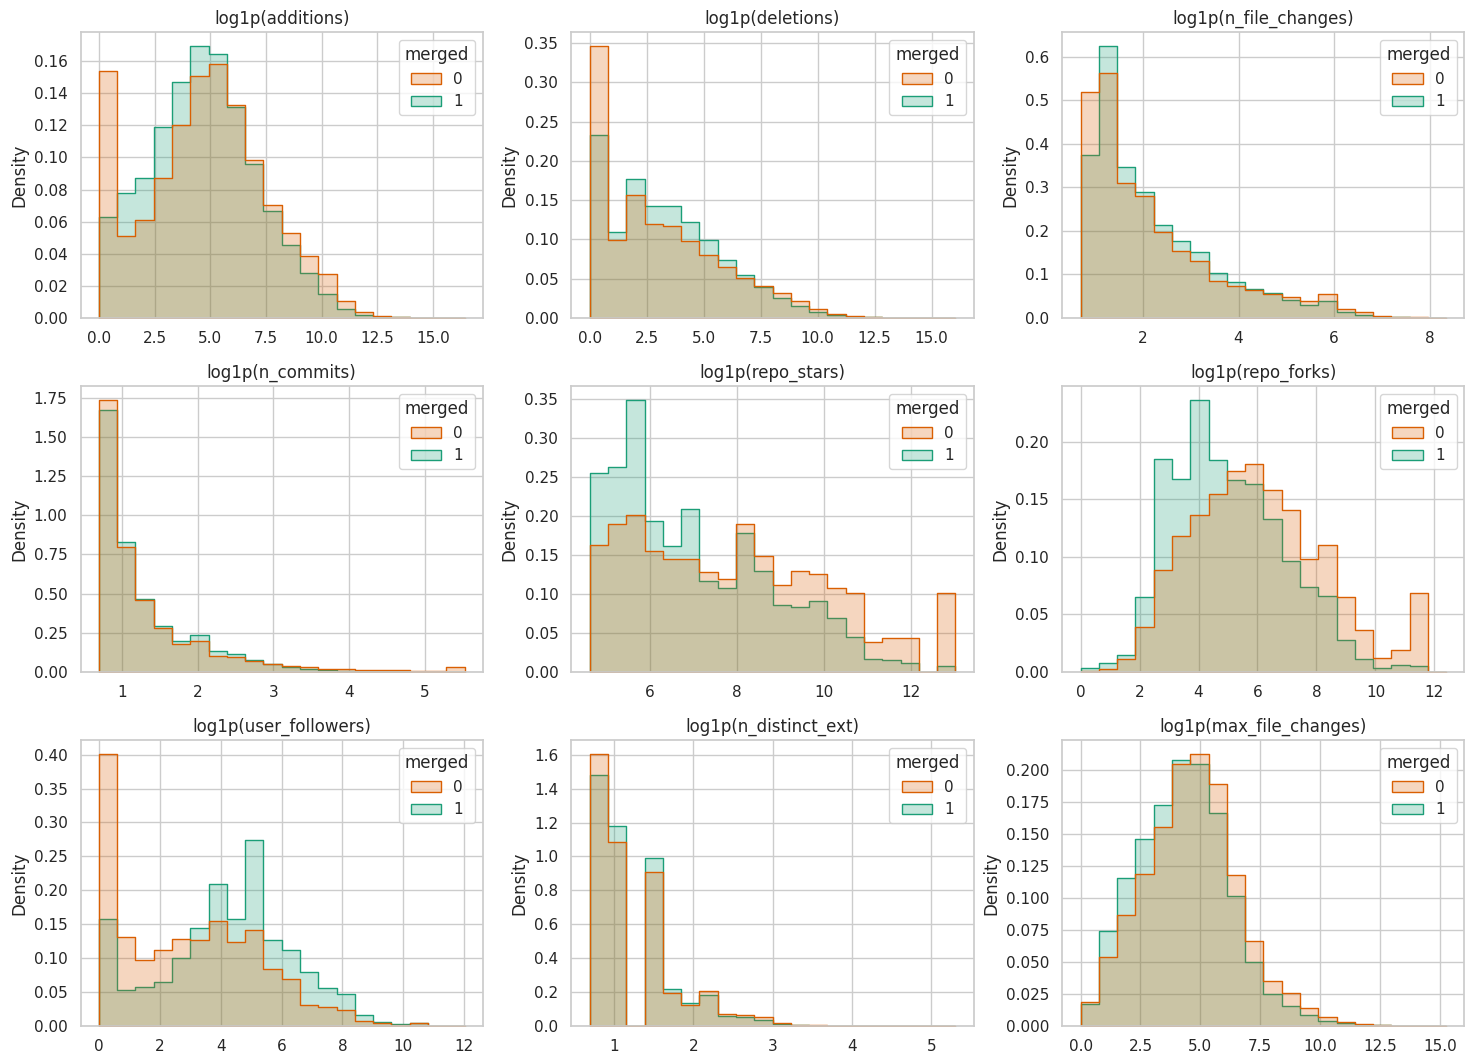

,median_not_merged,median_merged,ratio_merged/not
additions,127.000,105.000,0.827
deletions,12.000,19.000,1.583
n_file_changes,5.000,5.000,1.000
n_commits,2.000,2.000,1.000
repo_stars,"2,495.000",754.000,0.302
repo_forks,347.000,118.000,0.340
user_followers,17.000,77.000,4.529
n_distinct_ext,2.000,2.000,1.000
max_file_changes,103.000,73.000,0.709


Interpretation: features whose medians differ clearly between classes (ratio far from 1) are likely useful predictors.


In [ ]:
plot_cols = [c for c in ["additions", "deletions", "n_file_changes", "n_commits", "repo_stars", "repo_forks",
                         "user_followers", "n_distinct_ext", "max_file_changes"] if c in df.columns]
n = len(plot_cols); ncols = 3; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.6 * nrows))
for ax, c in zip(axes.ravel(), plot_cols):
    tmp = pd.DataFrame({c: np.log1p(df[c].clip(lower=0)), "merged": df["merged"]}).dropna()
    sns.histplot(data=tmp, x=c, hue="merged", bins=20, stat="density", common_norm=False,
                 element="step", ax=ax, palette={0: "#d95f02", 1: "#1b9e77"})
    ax.set_title(f"log1p({c})"); ax.set_xlabel("")
for ax in axes.ravel()[n:]:
    ax.remove()
plt.tight_layout(); save_fig("03_numeric_distributions_by_class"); plt.show()

med = df.groupby("merged")[plot_cols].median().T
med.columns = ["median_not_merged", "median_merged"]
med["ratio_merged/not"] = med["median_merged"] / med["median_not_merged"].replace(0, np.nan)
display(med)
print("Interpretation: features whose medians differ clearly between classes (ratio far from 1) are likely useful predictors.")

### 7.4 Outliers — box plots, IQR and Z-score

figure saved -> /content/drive/MyDrive/CME519_AIDev/figures/04_boxplots_by_class.png


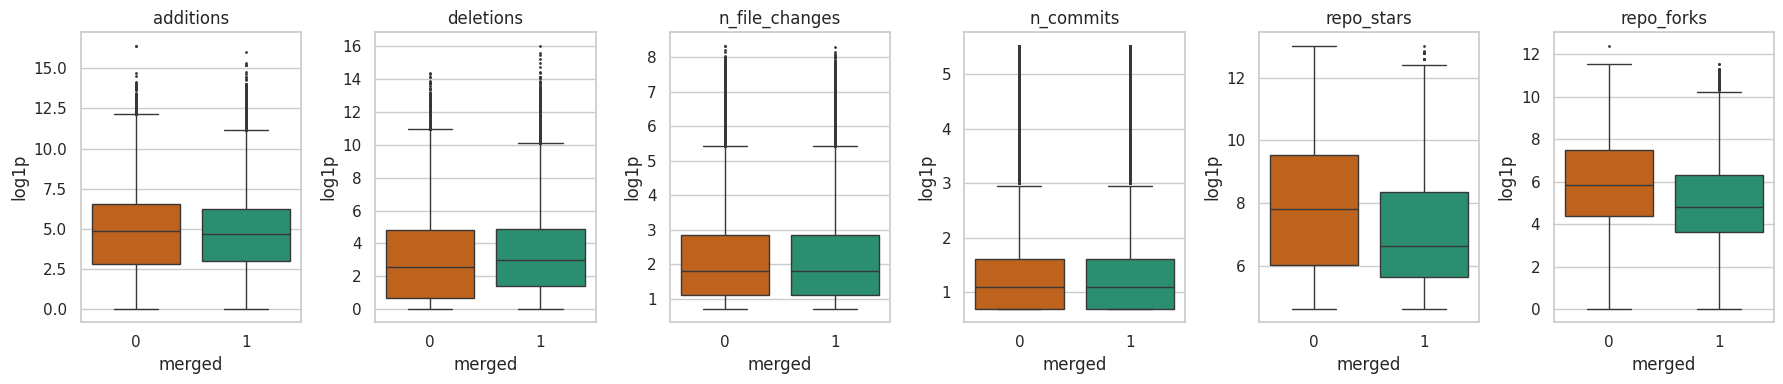

,Q1,Q3,IQR,lower_bound,upper_bound,IQR_outlier_%,Zscore_|z|>3_%
feature,,,,,,,
n_doc_files,0.000,1.000,1.000,-1.500,2.500,17.650,0.890
deletions,2.000,128.250,126.250,-187.380,317.620,16.760,0.170
repo_stars,298.000,"5,382.000","5,084.000","-7,328.000","13,008.000",16.010,1.960
changes,29.000,767.000,738.000,"-1,078.000","1,874.000",15.860,0.220
additions,18.000,560.000,542.000,-795.000,"1,373.000",15.660,0.180
repo_forks,42.000,733.000,691.000,-994.500,"1,769.500",14.900,1.980
n_file_changes,2.000,16.000,14.000,-19.000,37.000,14.190,1.690
n_added_files,0.000,2.000,2.000,-3.000,5.000,14.160,1.390
user_followers,10.000,215.000,205.000,-297.500,522.500,13.500,0.800


Interpretation: the IQR rule flags far more points than |z| > 3 because the distributions are skewed. Large PRs and very popular repositories are real (not errors), so outliers will be capped/log-transformed rather than deleted (compared in Notebook 2).


In [ ]:
box_cols = plot_cols[:6]
fig, axes = plt.subplots(1, len(box_cols), figsize=(3 * len(box_cols), 4))
for ax, c in zip(axes, box_cols):
    sns.boxplot(x=df["merged"], y=np.log1p(df[c].clip(lower=0)), ax=ax, palette=["#d95f02", "#1b9e77"], fliersize=1)
    ax.set_title(c); ax.set_xlabel("merged"); ax.set_ylabel("log1p")
plt.tight_layout(); save_fig("04_boxplots_by_class"); plt.show()

rows = []
for c in NUM:
    s = df[c].dropna()
    if s.empty:
        continue
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (s - s.mean()) / s.std(ddof=0) if s.std(ddof=0) > 0 else s * 0
    rows.append({"feature": c, "Q1": q1, "Q3": q3, "IQR": iqr, "lower_bound": lo, "upper_bound": hi,
                 "IQR_outlier_%": ((s < lo) | (s > hi)).mean() * 100,
                 "Zscore_|z|>3_%": (z.abs() > 3).mean() * 100})
out_tbl = pd.DataFrame(rows).set_index("feature").sort_values("IQR_outlier_%", ascending=False)
display(out_tbl.round(2))
print("Interpretation: the IQR rule flags far more points than |z| > 3 because the distributions are skewed. "
      "Large PRs and very popular repositories are real (not errors), so outliers will be capped/log-transformed "
      "rather than deleted (compared in Notebook 2).")

### 7.5 Categorical features vs. target

figure saved -> /content/drive/MyDrive/CME519_AIDev/figures/05_merge_rate_agent_language.png


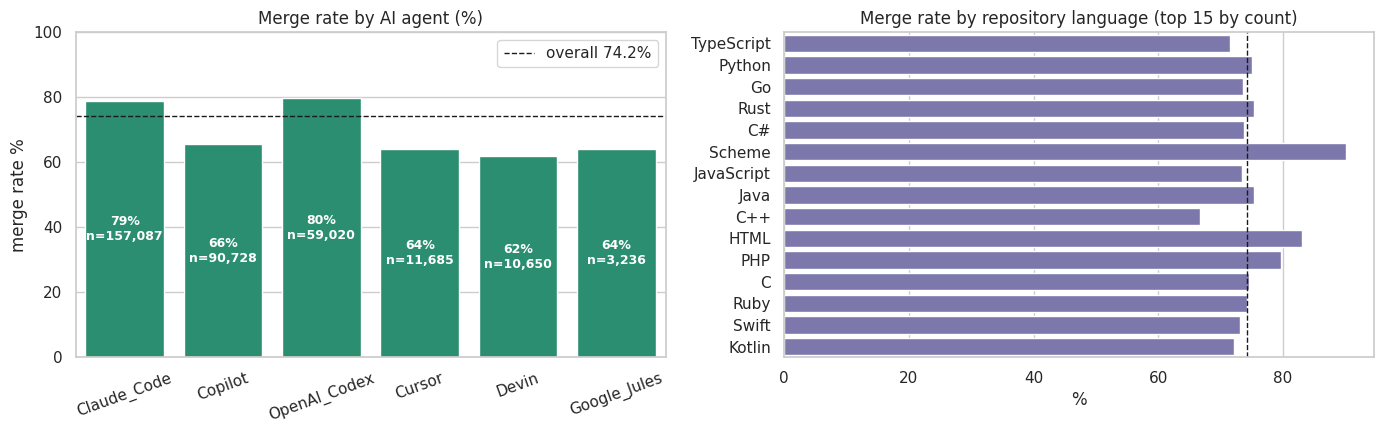

,n,merge_rate
agent,,
Claude_Code,157087,78.800
Copilot,90728,65.700
OpenAI_Codex,59020,79.900
Cursor,11685,64.000
Devin,10650,61.900
Google_Jules,3236,64.100


Interpretation: overall merge rate 74.2%. Highest agent: OpenAI_Codex (79.9%), lowest: Devin (61.9%). The agent alone changes the merge probability, so it is a strong categorical feature. Agents also differ a lot in volume -> one-hot encoding with all categories kept.


In [ ]:
def rate_table(col, top=None, min_n=50):
    t = df.groupby(col, dropna=False)["merged"].agg(n="size", merge_rate="mean")
    t = t[t["n"] >= min_n].sort_values("n", ascending=False)
    if top:
        t = t.head(top)
    t["merge_rate"] = (t["merge_rate"] * 100).round(1)
    return t

overall = df["merged"].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
t_agent = rate_table("agent")
sns.barplot(x=t_agent.index.astype(str), y=t_agent["merge_rate"], ax=axes[0], color="#1b9e77")
axes[0].axhline(overall, ls="--", c="k", lw=1, label=f"overall {overall:.1f}%"); axes[0].legend()
axes[0].set_title("Merge rate by AI agent (%)"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=20)
axes[0].set_ylim(0, 100); axes[0].set_ylabel("merge rate %")
for i, (r, nn) in enumerate(zip(t_agent["merge_rate"], t_agent["n"])):
    axes[0].text(i, r / 2, f"{r:.0f}%\nn={nn:,}", ha="center", va="center", fontsize=9, color="white", fontweight="bold")

t_lang = rate_table("repo_language", top=15)
sns.barplot(y=t_lang.index.astype(str), x=t_lang["merge_rate"], ax=axes[1], color="#7570b3")
axes[1].axvline(overall, ls="--", c="k", lw=1)
axes[1].set_title("Merge rate by repository language (top 15 by count)"); axes[1].set_ylabel(""); axes[1].set_xlabel("%")
plt.tight_layout(); save_fig("05_merge_rate_agent_language"); plt.show()

display(t_agent)
print(f"Interpretation: overall merge rate {overall:.1f}%. Highest agent: {t_agent['merge_rate'].idxmax()} "
      f"({t_agent['merge_rate'].max():.1f}%), lowest: {t_agent['merge_rate'].idxmin()} ({t_agent['merge_rate'].min():.1f}%). "
      f"The agent alone changes the merge probability, so it is a strong categorical feature. "
      f"Agents also differ a lot in volume -> one-hot encoding with all categories kept.")

In [ ]:
for col in ["repo_license", "repo_is_forked"]:
    if col in df.columns:
        t = rate_table(col, top=10)
        print(f"\n{col}: {df[col].nunique(dropna=True)} distinct values, {df[col].isna().mean()*100:.1f}% missing")
        display(t)
card = df[CAT].nunique(dropna=True).rename("n_unique").to_frame()
display(card)
print("Interpretation: 'repo_language' and 'repo_license' have many rare categories -> rare levels will be grouped "
      "into 'Other' before one-hot encoding (high-cardinality handling, Notebook 2).")


repo_license: 38 distinct values, 4.5% missing


,n,merge_rate
repo_license,,
MIT,146315,73.200
Apache-2.0,71328,75.800
NOASSERTION,54087,75.300
NaN,14827,76.300
AGPL-3.0,14646,72.900
GPL-3.0,13833,70.500
BSD-3-Clause,5361,79.300
GPL-2.0,2763,72.500
LGPL-3.0,2073,77.500



repo_is_forked: 2 distinct values, 0.0% missing


,n,merge_rate
repo_is_forked,,
False,329988,74.300
True,2418,72.000


,n_unique
agent,6
repo_language,184
repo_license,38
repo_is_forked,2


Interpretation: 'repo_language' and 'repo_license' have many rare categories -> rare levels will be grouped into 'Other' before one-hot encoding (high-cardinality handling, Notebook 2).


### 7.6 Temporal patterns (PR creation time)

Dates cannot be used directly by the models. These plots show which date parts carry signal and should be engineered as features (Notebook 2).

figure saved -> /content/drive/MyDrive/CME519_AIDev/figures/06_temporal_patterns.png


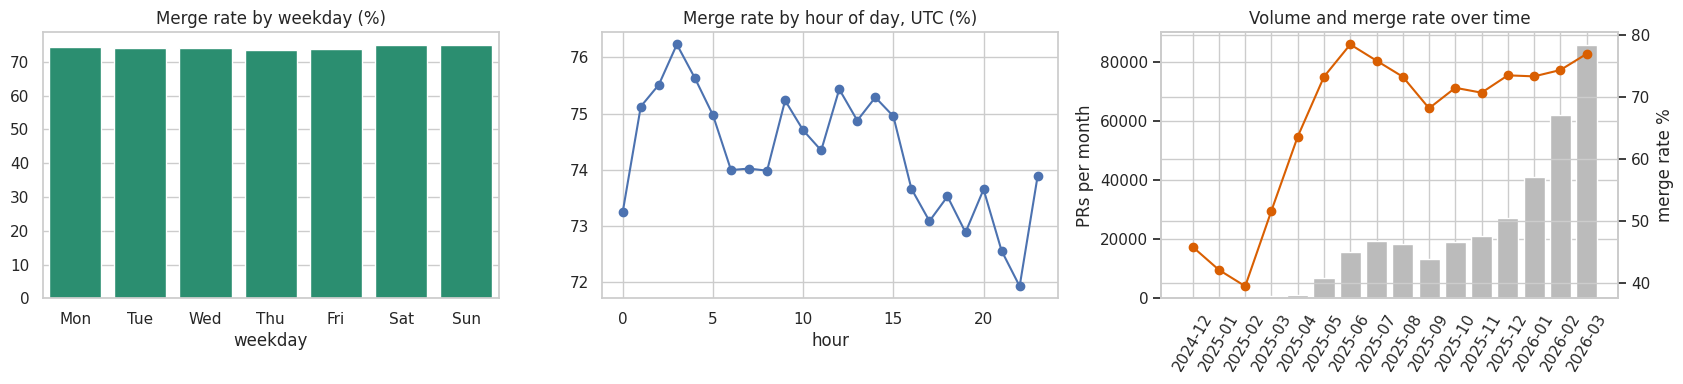

Data period: 2024-12-24 -> 2026-03-31
Weekday merge rate range: 73.6% - 75.0% | hour range: 71.9% - 76.2%
Interpretation: differences across weekday/hour/month suggest engineering hour, weekday, weekend flag and month from 'created_at'. The time trend also means a random split mixes periods (limitation noted for the report).


In [ ]:
t = df[["created_at", "merged"]].dropna().copy()
t["weekday"] = t["created_at"].dt.day_name().str[:3]
t["hour"] = t["created_at"].dt.hour
t["month"] = t["created_at"].dt.to_period("M").astype(str)
order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
wd = t.groupby("weekday")["merged"].mean().reindex(order) * 100
sns.barplot(x=wd.index, y=wd.values, ax=axes[0], color="#1b9e77"); axes[0].set_title("Merge rate by weekday (%)")
hr = t.groupby("hour")["merged"].mean() * 100
axes[1].plot(hr.index, hr.values, marker="o"); axes[1].set_title("Merge rate by hour of day, UTC (%)"); axes[1].set_xlabel("hour")
mo = t.groupby("month").agg(n=("merged", "size"), rate=("merged", "mean"))
axes[2].bar(mo.index, mo["n"], color="#bbbbbb"); axes[2].set_ylabel("PRs per month")
ax2 = axes[2].twinx(); ax2.plot(mo.index, mo["rate"] * 100, c="#d95f02", marker="o"); ax2.set_ylabel("merge rate %")
axes[2].set_title("Volume and merge rate over time"); axes[2].tick_params(axis="x", rotation=60)
plt.tight_layout(); save_fig("06_temporal_patterns"); plt.show()

print(f"Data period: {t['created_at'].min().date()} -> {t['created_at'].max().date()}")
print(f"Weekday merge rate range: {wd.min():.1f}% - {wd.max():.1f}% | hour range: {hr.min():.1f}% - {hr.max():.1f}%")
print("Interpretation: differences across weekday/hour/month suggest engineering hour, weekday, weekend flag and "
      "month from 'created_at'. The time trend also means a random split mixes periods (limitation noted for the report).")

### 7.7 Text fields — title and body

figure saved -> /content/drive/MyDrive/CME519_AIDev/figures/07_text_features.png


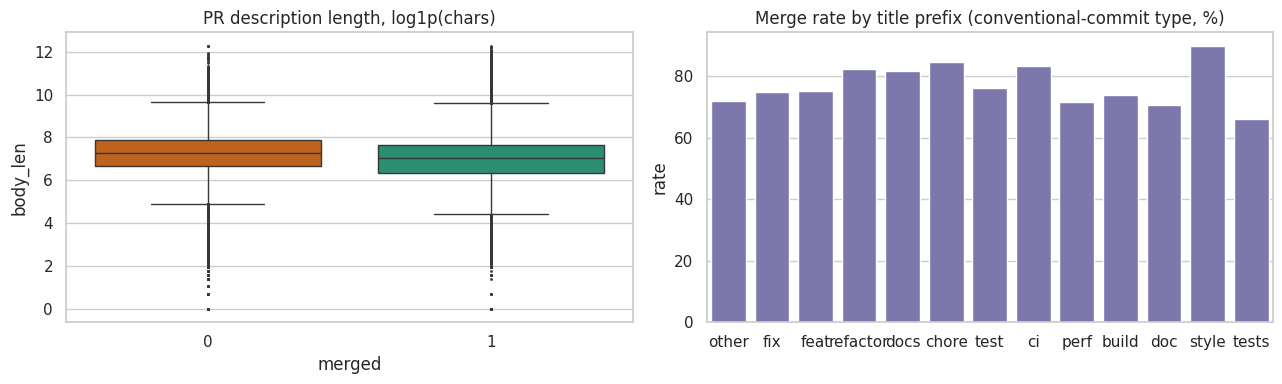

,n,rate
title_type,,
other,158489,71.800
fix,89897,74.900
feat,45314,75.300
refactor,10800,82.300
docs,10311,81.800
chore,8991,84.700
test,3032,76.200
ci,2372,83.200
perf,2070,71.600


PRs with an empty description: 0.5%
Interpretation: title/body length, empty-description flag and the title type (feat/fix/docs/...) will be engineered as numeric/categorical features in Notebook 2; the raw text is not used directly.


In [ ]:
txt = pd.DataFrame({
    "title_len": df["title"].fillna("").str.len(),
    "body_len": df["body"].fillna("").str.len(),
    "has_body": df["body"].fillna("").str.strip().ne("").astype(int),
    "title_type": df["title"].fillna("").str.lower().str.extract(
        r"^\s*(feat|fix|docs|doc|chore|refactor|test|tests|ci|build|perf|style)\b", expand=False).fillna("other"),
    "merged": df["merged"],
})
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(x=txt["merged"], y=np.log1p(txt["body_len"]), ax=axes[0], palette=["#d95f02", "#1b9e77"], fliersize=1)
axes[0].set_title("PR description length, log1p(chars)")
tt = txt.groupby("title_type")["merged"].agg(n="size", rate="mean").sort_values("n", ascending=False)
sns.barplot(x=tt.index, y=tt["rate"] * 100, ax=axes[1], color="#7570b3")
axes[1].set_title("Merge rate by title prefix (conventional-commit type, %)"); axes[1].set_xlabel("")
plt.tight_layout(); save_fig("07_text_features"); plt.show()

display(tt.assign(rate=lambda x: (x["rate"] * 100).round(1)))
print(f"PRs with an empty description: {100 - txt['has_body'].mean()*100:.1f}%")
print("Interpretation: title/body length, empty-description flag and the title type (feat/fix/docs/...) will be "
      "engineered as numeric/categorical features in Notebook 2; the raw text is not used directly.")

### 7.8 Correlations

Spearman correlation is used because the features are skewed and not normally distributed.

figure saved -> /content/drive/MyDrive/CME519_AIDev/figures/08_correlation_heatmap.png


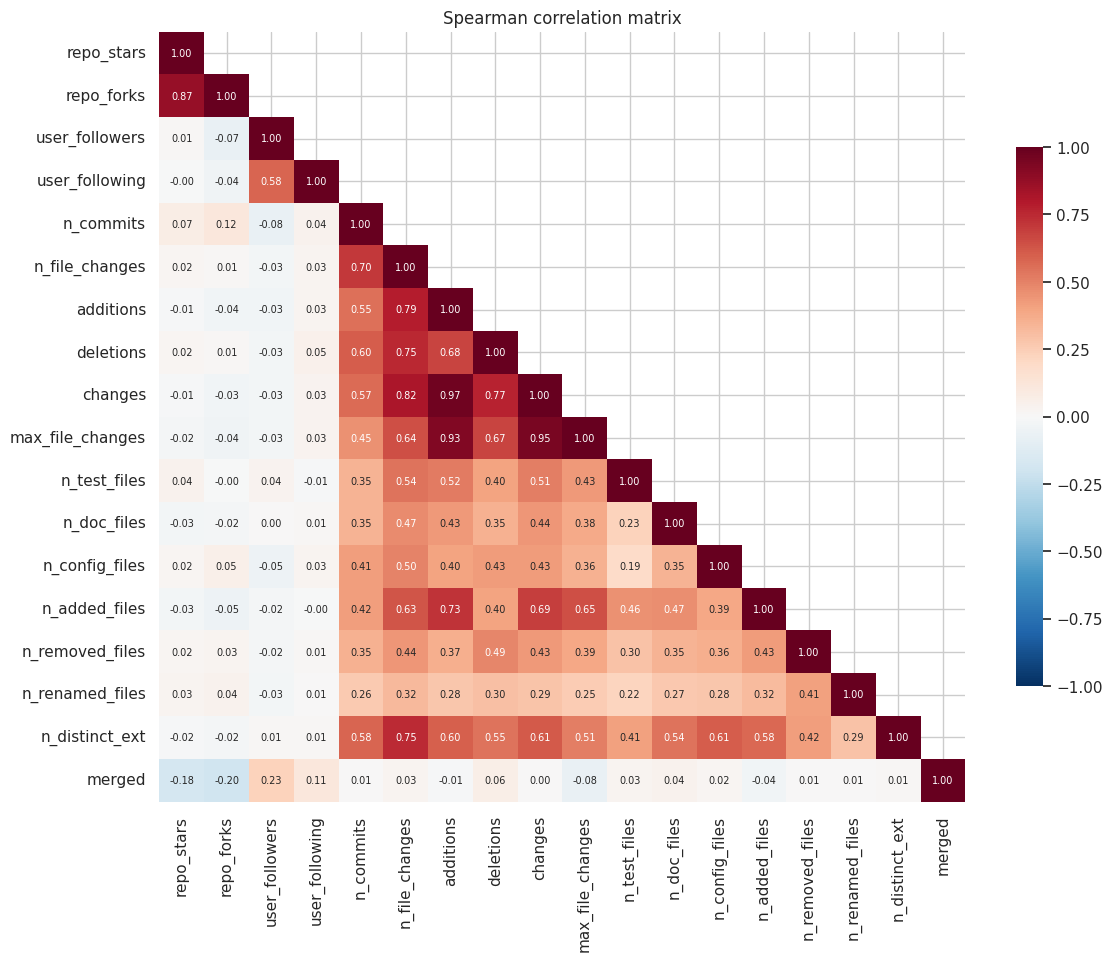

Correlation with target (|rho| sorted):
user_followers      0.233
repo_forks         -0.203
repo_stars         -0.177
user_following      0.115
max_file_changes   -0.076
deletions           0.063
n_doc_files         0.040
n_added_files      -0.036
n_test_files        0.029
n_file_changes      0.027
n_config_files      0.017
n_distinct_ext      0.012
additions          -0.011
n_commits           0.007
n_removed_files     0.006
n_renamed_files     0.006
changes             0.002

Highly correlated feature pairs (|rho| > 0.85): 4


,level_0,level_1,rho
88,additions,changes,0.972
108,changes,max_file_changes,0.953
89,additions,max_file_changes,0.929
0,repo_stars,repo_forks,0.872


Interpretation: pairs with |rho| > 0.85 (e.g. changes vs additions) carry almost the same information; one of each pair is a candidate for removal in the correlation-filter step of feature selection.


In [ ]:
corr_cols = NUM + ["merged"]
corr = df[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Spearman correlation matrix")
save_fig("08_correlation_heatmap"); plt.show()

with_target = corr["merged"].drop("merged").sort_values(key=np.abs, ascending=False)
print("Correlation with target (|rho| sorted):"); print(with_target.round(3).to_string())
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("rho").reset_index().query("level_0 != 'merged' and level_1 != 'merged'"))
high = pairs[pairs["rho"].abs() > 0.85].sort_values("rho", ascending=False)
print(f"\nHighly correlated feature pairs (|rho| > 0.85): {len(high)}")
display(high)
print("Interpretation: pairs with |rho| > 0.85 (e.g. changes vs additions) carry almost the same information; "
      "one of each pair is a candidate for removal in the correlation-filter step of feature selection.")

figure saved -> /content/drive/MyDrive/CME519_AIDev/figures/09_scatter_additions_deletions.png


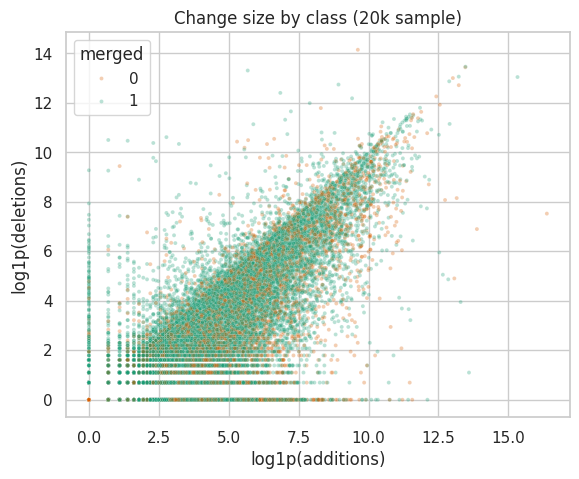

Interpretation: the two classes overlap strongly in change size alone, so no single feature separates them; a combination of agent, repository and change features is needed (multivariate model).


In [ ]:
s = df[["additions", "deletions", "merged"]].dropna()
s = s.sample(min(20_000, len(s)), random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.scatterplot(x=np.log1p(s["additions"]), y=np.log1p(s["deletions"]), hue=s["merged"], alpha=.3, s=8,
                palette={0: "#d95f02", 1: "#1b9e77"}, ax=ax)
ax.set_xlabel("log1p(additions)"); ax.set_ylabel("log1p(deletions)"); ax.set_title("Change size by class (20k sample)")
save_fig("09_scatter_additions_deletions"); plt.show()
print("Interpretation: the two classes overlap strongly in change size alone, so no single feature separates them; "
      "a combination of agent, repository and change features is needed (multivariate model).")

### 7.9 Leakage check — why post-creation fields are excluded

`closed_at` and `merged_at` are only known after the decision. The plot shows that time-to-close is very different for the two classes, so a model would "learn the answer" from it. These fields are removed before modeling.

figure saved -> /content/drive/MyDrive/CME519_AIDev/figures/10_leakage_time_to_close.png


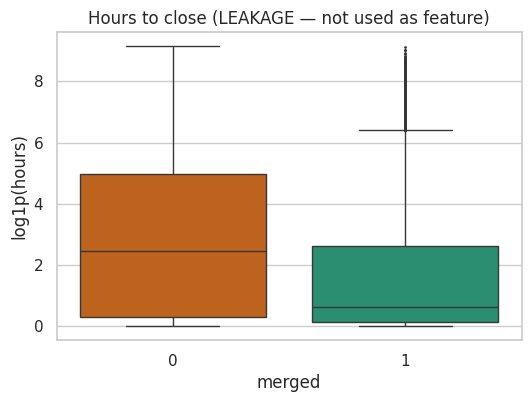

merged
0   10.517
1    0.881
Excluded leakage columns: ['state', 'closed_at', 'merged_at', 'time to close', 'reviews', 'comments', 'timeline events']


In [ ]:
ttc = ((df["closed_at"] - df["created_at"]).dt.total_seconds() / 3600).rename("hours_to_close")
tmp = pd.DataFrame({"hours_to_close": ttc, "merged": df["merged"]}).dropna()
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(x=tmp["merged"], y=np.log1p(tmp["hours_to_close"].clip(lower=0)), ax=ax, palette=["#d95f02", "#1b9e77"], fliersize=1)
ax.set_title("Hours to close (LEAKAGE — not used as feature)"); ax.set_ylabel("log1p(hours)")
save_fig("10_leakage_time_to_close"); plt.show()
print(tmp.groupby("merged")["hours_to_close"].median().rename("median hours to close").to_string())
print("Excluded leakage columns:", ROLES["leakage_excluded"] + ["time to close", "reviews", "comments", "timeline events"])

## 8. Summary of EDA findings

In [ ]:
print("DATASET")
print(f"  - {len(df):,} closed PRs (rows) after integration; {df['repo_id'].nunique():,} repositories; agents: {df['agent'].nunique()}")
print(f"  - candidate features: {len(NUM)} numeric, {len(CAT)} categorical, 2 datetime, 2 text (before engineering)")
print(f"  - target: merged = {df['merged'].mean()*100:.1f}%  /  not merged = {(1-df['merged'].mean())*100:.1f}%  -> imbalanced")
print("DATA QUALITY")
print(f"  - columns with missing values: {len(miss)}; max missing = {miss['missing_%'].max() if len(miss) else 0:.1f}%")
print(f"  - highly skewed numeric features: {len(skewed)} / {len(NUM)} -> median imputation, log1p / capping")
print(f"  - highly correlated pairs (|rho|>0.85): {len(high)} -> correlation filter in feature selection")
print("SIGNAL")
print(f"  - merge rate by agent ranges {t_agent['merge_rate'].min():.1f}% - {t_agent['merge_rate'].max():.1f}%")
print(f"  - strongest single numeric correlation with target: {with_target.index[0]} (rho = {with_target.iloc[0]:.3f})")
print("NEXT (Notebook 2): train/test split first -> imputation, outlier treatment, encoding, scaling, "
      "date/text feature engineering, and comparison of feature-selection methods.")

DATASET
  - 332,406 closed PRs (rows) after integration; 22,357 repositories; agents: 6
  - candidate features: 17 numeric, 4 categorical, 2 datetime, 2 text (before engineering)
  - target: merged = 74.2%  /  not merged = 25.8%  -> imbalanced
DATA QUALITY
  - columns with missing values: 19; max missing = 27.3%
  - highly skewed numeric features: 17 / 17 -> median imputation, log1p / capping
  - highly correlated pairs (|rho|>0.85): 4 -> correlation filter in feature selection
SIGNAL
  - merge rate by agent ranges 61.9% - 79.9%
  - strongest single numeric correlation with target: user_followers (rho = 0.233)
NEXT (Notebook 2): train/test split first -> imputation, outlier treatment, encoding, scaling, date/text feature engineering, and comparison of feature-selection methods.


---
**Files produced:** `data/pr_level.parquet` (input of Notebook 2) and `figures/01–10_*.png` (used in the IEEE report).